# YOLOv8 Drone Detection Training

Complete notebook for training YOLOv8 on your custom drone dataset.

## Dataset Format
- Images: JPG files in train/val/test folders
- Labels: YOLO format (class_id x_center y_center width height - normalized)
- Class: 0 = drone

## 1. Install Required Packages

In [2]:
# Install Ultralytics YOLO
!pip install ultralytics

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.1/1.1 MB 18.4 MB/s eta 0:00:00


In [3]:
# Verify GPU is available
import torch
print(f"CUDA available: {torch.cuda.is_available()}")
if torch.cuda.is_available():
    print(f"Device: {torch.cuda.get_device_name(0)}")
else:
    print("WARNING: Running on CPU. Go to Runtime -> Change runtime type -> Hardware accelerator -> GPU")

CUDA available: False


## 2. Mount Google Drive

We need access to your Drive to get the dataset and save the results.

In [4]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


## 3. Prepare Data

Copying data from Drive to the local Colab VM (`/content`) is much faster for training than reading directly from Drive.

**Option 1:** If your dataset is already in Drive as a folder, we'll copy it.
**Option 2:** If your dataset is zipped, we'll unzip it.

In [5]:
import os
import shutil
from pathlib import Path

# Define paths (Change these if your drive structure is different)
drive_project_path = '/content/drive/MyDrive/yolov8_project'
zip_path = f'{drive_project_path}/dataset.zip'
dataset_root = '/content/dataset'

if not os.path.exists(zip_path):
    print(f"Error: Could not find {zip_path}. Please make sure you uploaded dataset.zip to the 'yolov8_project' folder in Drive.")
else:
    print("Found dataset zip.")

    # Unzip
    if os.path.exists(dataset_root):
        shutil.rmtree(dataset_root)
    os.makedirs(dataset_root, exist_ok=True)

    print("Unzipping...")
    !unzip -q "{zip_path}" -d "{dataset_root}"
    print("Unzip complete.")

Found dataset zip.
Unzipping...
Unzip complete.


In [ ]:
import os
import shutil
import yaml
from pathlib import Path
from ultralytics import YOLO
import torch

# Set device
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f'Using device: {device}')


## 5. Configuration

Configure your dataset paths and training parameters here. Adjust these values based on your needs.


In [ ]:
# ========== CONFIGURATION ==========
# Dataset paths
drive_project_path = '/content/drive/MyDrive/yolov8_project'
dataset_root = '/content/dataset'

# Training parameters
MODEL_NAME = 'yolov8n.yaml'  # Options: yolov8n.yaml, yolov8s.yaml, yolov8m.yaml, yolov8l.yaml, yolov8x.yaml
NUM_EPOCHS = 50              # Number of training epochs
IMAGE_SIZE = 640             # Input image size
BATCH_SIZE = 16              # Batch size
DATA_YAML_PATH = '/content/data.yaml'

# Project settings
PROJECT_DIR = '/content/runs/detect'
RUN_NAME = 'train_drone_colab'

# Verify GPU is available
print("Configuration loaded!")
print(f"CUDA available: {torch.cuda.is_available()}")
if torch.cuda.is_available():
    print(f"Device: {torch.cuda.get_device_name(0)}")
    print(f"GPU Memory: {torch.cuda.get_device_properties(0).total_memory / 1024**3:.2f} GB")
else:
    print("WARNING: Running on CPU. Go to Runtime -> Change runtime type -> Hardware accelerator -> GPU")
print(f"\nTraining settings:")
print(f"  Model: {MODEL_NAME}")
print(f"  Batch size: {BATCH_SIZE}")
print(f"  Image size: {IMAGE_SIZE}x{IMAGE_SIZE}")
print(f"  Epochs: {NUM_EPOCHS}")


## 6. Create Configuration File

We need to create a `data.yaml` that points to the local `/content/dataset` locations.


In [ ]:
# Check where the unzip actually put the files.
# Sometimes it unzips as /content/dataset/drone_dataset_split/... or just /content/dataset/...
# We'll look for the 'images' folder.
base_path = Path(dataset_root)
found_images = list(base_path.rglob('images'))

if not found_images:
    print("Error: Could not find 'images' folder after unzip.")
else:
    # Take the parent of the first 'images' folder found as the data root
    data_root = found_images[0].parent
    print(f"Data root located at: {data_root}")

    # Create data.yaml
    data_yaml = {
        'path': str(data_root),
        'train': 'images/train',
        'val': 'images/val',
        'test': 'images/test',
        'names': {0: 'drone'}
    }

    with open(DATA_YAML_PATH, 'w') as f:
        yaml.dump(data_yaml, f)

    print("Created /content/data.yaml")
    !cat {DATA_YAML_PATH}


## 7. Initialize Model

Now we'll create the YOLOv8 model. YOLOv8n is the smallest and fastest, perfect for getting started.


In [ ]:
# Initialize YOLOv8 model
print(f"Initializing {MODEL_NAME}...")

model = YOLO(MODEL_NAME)

print(f"Model created successfully!")
print(f"Model: {MODEL_NAME}")


## 8. Train Model

This is where the magic happens! The model will learn to detect drones in your images. Training may take a while depending on your dataset size and number of epochs.

**Note:** The best model (lowest validation loss) will be saved automatically during training.


In [ ]:
print("=" * 60)
print("Starting training...")
print(f"Training for {NUM_EPOCHS} epochs")
print(f"Device: {device}")
print(f"Model: {MODEL_NAME}")
print("=" * 60)

# Train
results = model.train(
    data=DATA_YAML_PATH,
    epochs=NUM_EPOCHS,
    imgsz=IMAGE_SIZE,
    batch=BATCH_SIZE,
    project=PROJECT_DIR,
    name=RUN_NAME,
    exist_ok=True
)


## 9. View Training History

Let's visualize how the training progressed over time. YOLOv8 automatically generates training plots that are saved in the runs directory.


In [ ]:
import matplotlib.pyplot as plt
from IPython.display import Image, display
import glob

# Display training results
results_dir = f'{PROJECT_DIR}/{RUN_NAME}'
results_image = f'{results_dir}/results.png'

if os.path.exists(results_image):
    print("Training results visualization:")
    display(Image(results_image))
else:
    print(f"Results image not found at {results_image}")
    print("Available files in results directory:")
    if os.path.exists(results_dir):
        print(glob.glob(f'{results_dir}/*'))


## 10. Evaluate Model

Let's evaluate the trained model on the test dataset to see how well it performs.


In [ ]:
# Load your best trained model from the training results
model_path = f'{results_dir}/weights/best.pt'
if os.path.exists(model_path):
    print(f"Loading best model from: {model_path}")
    model = YOLO(model_path)
    
    # Run validation on the test split defined in data.yaml
    print("\nEvaluating on test dataset...")
    metrics = model.val(data=DATA_YAML_PATH, split='test')
    
    print(f"\nEvaluation Results:")
    print(f"  mAP50-95: {metrics.box.map:.4f}")
    print(f"  mAP50: {metrics.box.map50:.4f}")
else:
    print(f"Model not found at {model_path}")
    print("Please ensure training completed successfully.")


## 11. Test Model on Validation Images

Let's see how well the model performs by visualizing predictions on some validation/test images.


In [ ]:
import random
import glob
from PIL import Image
from IPython.display import display

# Path to your test images based on your dataset root
test_images_path = f'{data_root}/images/test/*.jpg'
test_images = glob.glob(test_images_path)

if not test_images:
    print("No images found in the test folder.")
else:
    # Select a random image
    random_image = random.choice(test_images)

    # Run prediction
    print(f"Predicting on: {random_image}")
    results = model.predict(source=random_image, conf=0.25)

    # Visualize the results
    for r in results:
        im_array = r.plot()  # plot a BGR numpy array of predictions
        im = Image.fromarray(im_array[..., ::-1])  # convert to RGB PIL image
        display(im)


## 12. Test Model on Uploaded Images

You can test the model on your own images by uploading them.


In [ ]:
from google.colab import files

# Ensure model is loaded
if 'model' not in locals() or model is None:
    model_path = f'{results_dir}/weights/best.pt'
    if os.path.exists(model_path):
        model = YOLO(model_path)
        print(f"Loaded model from: {model_path}")
    else:
        print("Error: Model not found. Please run training first.")

# Upload your image
print("Please select an image to upload:")
uploaded = files.upload()

# Process the uploaded file(s)
for filename in uploaded.keys():
    print(f'\nRunning prediction on: {filename}')

    # Run prediction
    results = model.predict(source=filename, conf=0.25)

    # Visualize and display the results
    for r in results:
        im_array = r.plot()  # plot a BGR numpy array of predictions
        im = Image.fromarray(im_array[..., ::-1])  # convert to RGB PIL image
        display(im)


## 13. Save Results to Drive

Compress the training results and copy them back to Google Drive for safekeeping.


In [ ]:
# Compress the training results
zip_path = f'{results_dir}/runs.zip'
!zip -r {zip_path} {results_dir}

# Copy to Drive
destination = f'{drive_project_path}/runs.zip'
shutil.copy2(zip_path, destination)

print(f"✓ Results saved to Google Drive: {destination}")
print("\n🎉 ALL DONE! Your trained model is saved in Google Drive.")


In [8]:
# 6. Evaluate on Test Data
from ultralytics import YOLO

# Load your best trained model from your Drive results path
model_path = '/content/drive/MyDrive/yolov8_project/runs/detect/train_drone_colab/weights/best.pt'
model = YOLO(model_path)

# Run validation on the test split defined in data.yaml
metrics = model.val(data='/content/data.yaml', split='test')

print(f"mAP50-95: {metrics.box.map}")
print(f"mAP50: {metrics.box.map50}")

Ultralytics 8.3.240 🚀 Python-3.12.12 torch-2.9.0+cpu CPU (Intel Xeon CPU @ 2.20GHz)
YOLOv8n summary (fused): 72 layers, 3,005,843 parameters, 0 gradients, 8.1 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1916.7±1349.0 MB/s, size: 291.9 KB)
val: Scanning /content/dataset/drone_dataset_split/labels/test.cache... 205 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 205/205 263.7Kit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 13/13 3.5s/it 45.6s
                   all        205        221      0.903      0.798       0.89      0.546
Speed: 3.8ms preprocess, 192.8ms inference, 0.0ms loss, 0.4ms postprocess per image
Results saved to /content/runs/detect/val2
mAP50-95: 0.5456084236472063
mAP50: 0.8901409602538424



image 1/1 /content/dataset/drone_dataset_split/images/test/foto04670.jpg: 384x640 1 drone, 142.2ms
Speed: 2.3ms preprocess, 142.2ms inference, 1.3ms postprocess per image at shape (1, 3, 384, 640)
Predicting on: /content/dataset/drone_dataset_split/images/test/foto04670.jpg


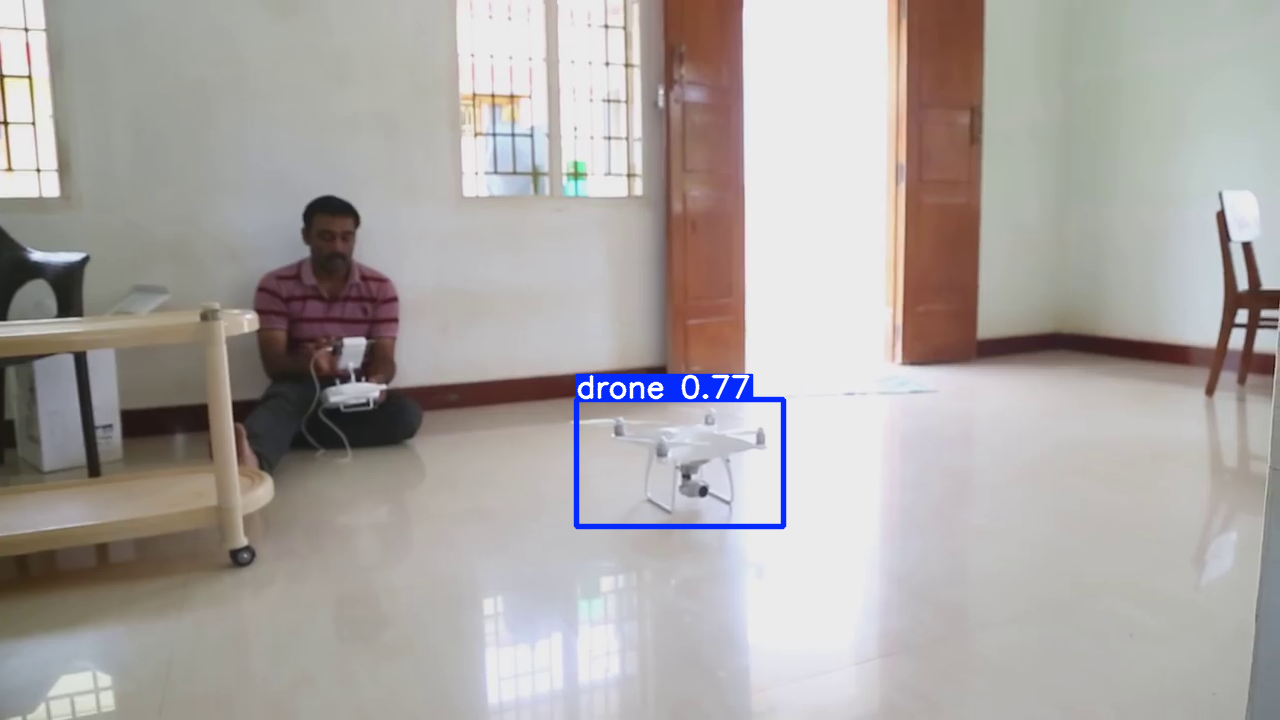

In [9]:
# 7. Inference on a Random Test Image
import random
import glob
from PIL import Image
from IPython.display import display

# Path to your test images based on your dataset root
test_images_path = '/content/dataset/drone_dataset_split/images/test/*.jpg'
test_images = glob.glob(test_images_path)

if not test_images:
    print("No images found in the test folder.")
else:
    # Select a random image
    random_image = random.choice(test_images)

    # Run prediction
    results = model.predict(source=random_image, conf=0.25)

    # Visualize the results
    for r in results:
        im_array = r.plot()  # plot a BGR numpy array of predictions
        im = Image.fromarray(im_array[..., ::-1])  # convert to RGB PIL image
        print(f"Predicting on: {random_image}")
        display(im)

testing on uploaded image :

Please select an image to upload:


Saving p31w.jpg to p31w.jpg
Running prediction on: p31w.jpg

image 1/1 /content/p31w.jpg: 384x640 1 drone, 122.6ms
Speed: 8.1ms preprocess, 122.6ms inference, 0.8ms postprocess per image at shape (1, 3, 384, 640)


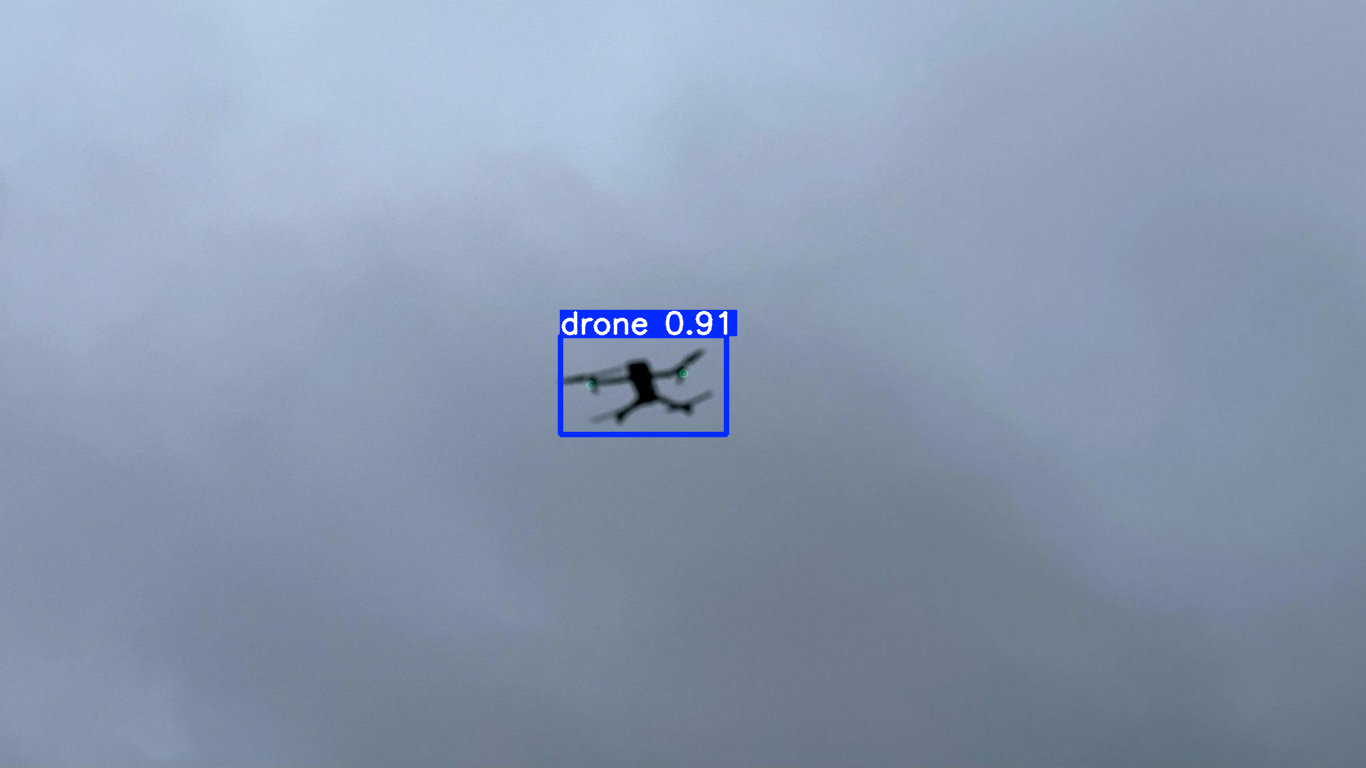

In [12]:
# 8. Inference on an Uploaded Image
from google.colab import files
from ultralytics import YOLO
from PIL import Image
import os

# 1. Load the model from your Drive results path
model_path = '/content/drive/MyDrive/yolov8_project/runs/detect/train_drone_colab/weights/best.pt'
model = YOLO(model_path)

# 2. Upload your image
print("Please select an image to upload:")
uploaded = files.upload()

# 3. Process the uploaded file(s)
for filename in uploaded.keys():
    print(f'Running prediction on: {filename}')

    # Run prediction
    results = model.predict(source=filename, conf=0.25)

    # Visualize and display the results
    for r in results:
        im_array = r.plot()  # plot a BGR numpy array of predictions
        im = Image.fromarray(im_array[..., ::-1])  # convert to RGB PIL image
        display(im)